<a href="https://colab.research.google.com/github/komazawa-deep-learning/komazawa-deep-learning.github.io/blob/master/2026notebooks/2026_1127pe_three_conditions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 位置符号化器 (PE) の効果: without PE, 正弦波 PE, RoPE の比較

百人一首の上の句をエンコーダで符号化し，下の句をデコーダで生成する Transformer で，
位置符号化器 (positional encoding; PE) を次の 3 通りに入れ替えて比較する。

| 条件 | 位置情報の入れ方 | 種類 |
|---|---|---|
| `none` | なし (NoPE) | — |
| `sinusoidal` | 埋め込みに正弦波を **加算** (Vaswani+ 2017) | 絶対位置 |
| `rope` | self-attention の Q, K を位置に応じて **回転** (Su+ 2021) | 相対位置 |

ここでは PE をエンコーダとデコーダの両方に同じ種類で入れる。
エンコーダとデコーダを別々に操作する実験は，もう一つのノートブック (`pe_2x2_shuffle.ipynb`) で行う。

* 共通コード: `pe_transformer.py` (モデル・学習・評価)
* データ: `chihaya.json` (百人一首 100 首)

### 2023 年版コードからの重要な修正
旧版では **デコーダの入力と教師信号が同じ系列** で，因果マスクも対角成分 (自分自身) を通していた。
そのためデコーダは「入力された文字をそのまま出す」だけで損失を下げられ，上の句を読む必要がなかった。
評価も正解の下の句をデコーダに与えたまま行っていた。この状態では **PE があってもなくても結果は同じ** になる (恒等写像は位置ごとに独立に計算できるため)。

本版では
* デコーダ入力 = `<SOS>` + 下の句，教師信号 = 下の句 + `<EOS>` (1 つずらす)
* 評価は上の句だけを与えて，下の句を 1 文字ずつ生成する (貪欲復号)

としている。

## 1. 準備

In [1]:
import os, sys, subprocess
IN_COLAB = 'google.colab' in sys.modules

REPO_URL = 'https://github.com/ShinAsakawa/CDP_ja.git'
NEEDED = ['pe_transformer.py', 'chihaya.json']

def find_dir():
    for d in ['.', 'CDP_ja']:
        if all(os.path.exists(os.path.join(d, f)) for f in NEEDED):
            return d
    return None

WORK_DIR = find_dir()
if WORK_DIR is None and IN_COLAB:
    if not os.path.exists('CDP_ja'):
        subprocess.run(['git', 'clone', '-q', REPO_URL], check=False)
    WORK_DIR = find_dir()
if WORK_DIR is None and IN_COLAB:
    from google.colab import files
    print('pe_transformer.py と chihaya.json をアップロードしてください')
    files.upload()
    WORK_DIR = find_dir()
assert WORK_DIR is not None, f'{NEEDED} が見つからない。このノートブックと同じフォルダに置くこと'
sys.path.insert(0, os.path.abspath(WORK_DIR))
DATA_PATH = os.path.join(WORK_DIR, 'chihaya.json')

# 日本語フォント
try:
    import japanize_matplotlib
except Exception:
    try:
        import matplotlib_fontja
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'matplotlib-fontja'], check=False)
        import matplotlib_fontja

%config InlineBackend.figure_format = 'retina'
import numpy as np
import torch
import matplotlib.pyplot as plt
import pe_transformer as pt

# デバイス: cuda (Colab GPU) > mps (Apple Silicon) > cpu
# このモデルは非常に小さいので，mps より cpu の方が速いことがある。その場合は下の行を有効にする
DEVICE = pt.get_device()
# DEVICE = torch.device('cpu')
print('Colab:', IN_COLAB, '| device:', DEVICE, '| torch:', torch.__version__, '| 作業フォルダ:', os.path.abspath(WORK_DIR))

Colab: True | device: cuda | torch: 2.14.1+cu130 | 作業フォルダ: /content/CDP_ja


In [2]:
pairs = pt.load_chihaya(DATA_PATH)   # [(上の句, 下の句), ...] ひらがな，濁点は除去して統一
vocab = pt.Vocab(pairs)
print('歌数:', len(pairs), '| 語彙数 (特殊トークン含む):', len(vocab))
print('上の句の最大長:', max(len(k) for k, _ in pairs), '| 下の句の最大長:', max(len(s) for _, s in pairs))
for k, s in pairs[:3]:
    print(f'  {k}  →  {s}')

歌数: 100 | 語彙数 (特殊トークン含む): 51
上の句の最大長: 19 | 下の句の最大長: 16
  あきのたのかりほのいほのとまをあらみ  →  わかころもてはつゆにぬれつつ
  はるすきてなつきにけらししろたへの  →  ころもほすてふあまのかくやま
  あしひきのやまとりのをのしたりをの  →  なかなかしよをひとりかもねむ


## 2. 2 種類の PE を目で見る

**正弦波 PE** は位置ごとに決まったベクトルを埋め込みに足す。下図の縦軸が位置，横軸が次元である。
左側の次元ほど速く (高周波)，右側の次元ほどゆっくり (低周波) 変化する。

**RoPE** は Q と K を位置に応じた角度だけ回転させる。そのため，位置 $m$ の Q と位置 $n$ の K の内積は
**相対位置 $n-m$ だけで決まり**，絶対位置には依存しない。下の数値でそれを確かめる。

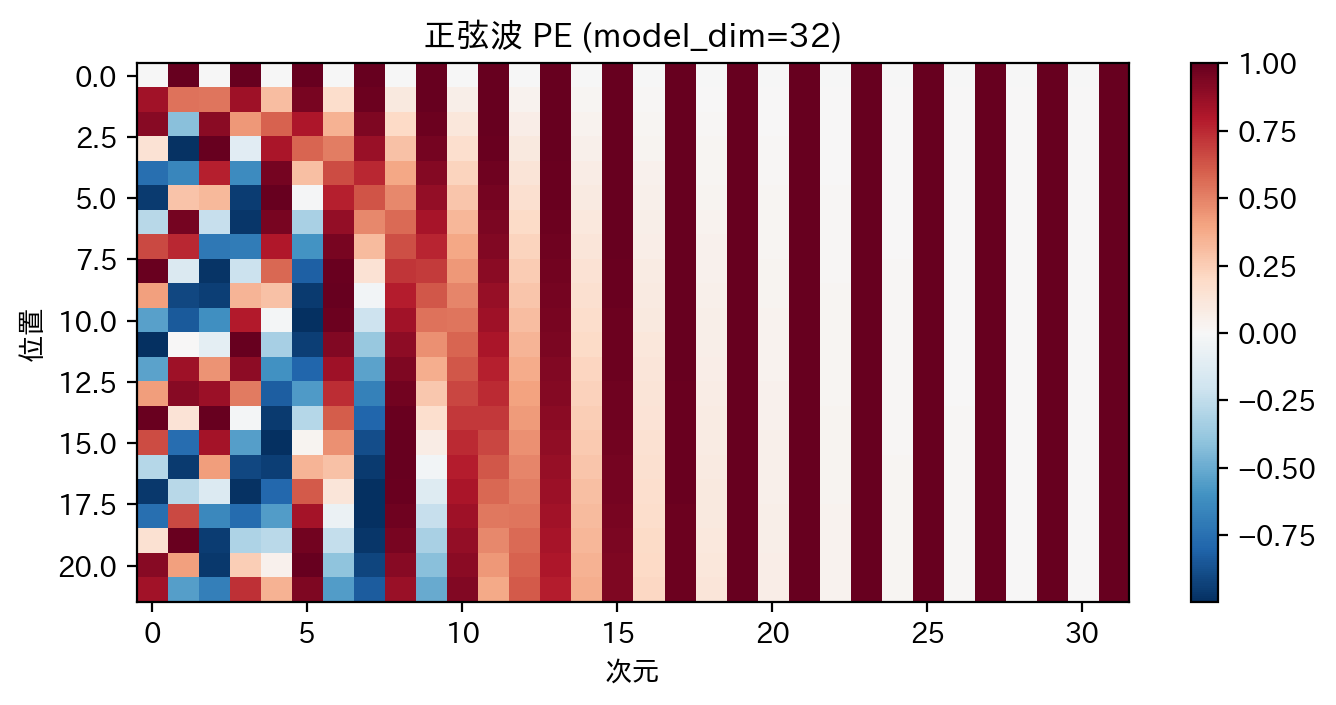

q の位置  0, k の位置  4 (相対位置 4) → 内積 +0.48492
q の位置 10, k の位置 14 (相対位置 4) → 内積 +0.48492
q の位置 30, k の位置 34 (相対位置 4) → 内積 +0.48492
q の位置  0, k の位置  1 (相対位置 1) → 内積 +0.65139
q の位置 20, k の位置 21 (相対位置 1) → 内積 +0.65139


In [3]:
model_dim, L = 32, 22
pe = pt.SinusoidalPE(model_dim)(torch.zeros(1, L, model_dim))[0]
plt.figure(figsize=(8, 3.5))
plt.imshow(pe.numpy(), aspect='auto', cmap='RdBu_r')
plt.colorbar(); plt.xlabel('次元'); plt.ylabel('位置'); plt.title('正弦波 PE (model_dim=32)')
plt.show()

# RoPE: 同じ q, k を異なる位置に置いて内積を比べる
torch.manual_seed(0)
rope = pt.RotaryPE(head_dim=8)
q, k = torch.randn(8), torch.randn(8)
Q = rope(q.expand(1, 1, 40, 8))[0, 0]   # 位置 0..39 に置いた q
K = rope(k.expand(1, 1, 40, 8))[0, 0]
for m, n in [(0, 4), (10, 14), (30, 34), (0, 1), (20, 21)]:
    print(f'q の位置 {m:2d}, k の位置 {n:2d} (相対位置 {n - m}) → 内積 {float(Q[m] @ K[n]):+.5f}')

## 3. 学習

* 3 条件 × 3 シード。シードを変えて，結果のばらつきも見る (1 回だけの比較では偶然の差と区別できない)。
* 学習率は cosine で徐々に下げる。固定学習率 (`lr_schedule='constant'`, 旧版と同じ) だと終盤に損失が跳ね上がることがあり，最終エポックの正解率が偶然に左右される。
* CPU で 1 条件あたり 20 秒前後かかる。合計で数分。

In [4]:
cfg = pt.Config(model_dim=32, num_heads=4, num_layers=1, ff_dim=32,
                epochs=300, batch_size=10, lr=1e-3, lr_schedule='cosine', eval_every=10)
CONDITIONS = ['none', 'sinusoidal', 'rope']
SEEDS = [0, 1, 2]

m_tmp = pt.build_model(cfg, len(vocab), 'rope', 'rope', DEVICE)
print('パラメータ数:', pt.count_params(m_tmp), '(どの条件でも同じ。PE には学習パラメータがない)')

results = {}   # (条件, シード) -> (model, history)
for pe_type in CONDITIONS:
    for seed in SEEDS:
        cfg.seed = seed
        results[(pe_type, seed)] = pt.train(cfg, pairs, vocab, enc_pe=pe_type, dec_pe=pe_type,
                                            device=DEVICE, verbose=False)
        h = results[(pe_type, seed)][1]
        print(f'{pe_type:>10s} seed={seed}: 最終 完全一致 {h["exact"][-1]:.2f}, 文字一致 {h["char"][-1]:.3f}')

パラメータ数: 22163 (どの条件でも同じ。PE には学習パラメータがない)
      none seed=0: 最終 完全一致 0.98, 文字一致 0.998
      none seed=1: 最終 完全一致 0.99, 文字一致 0.999
      none seed=2: 最終 完全一致 1.00, 文字一致 1.000
sinusoidal seed=0: 最終 完全一致 1.00, 文字一致 1.000
sinusoidal seed=1: 最終 完全一致 1.00, 文字一致 1.000
sinusoidal seed=2: 最終 完全一致 1.00, 文字一致 1.000
      rope seed=0: 最終 完全一致 1.00, 文字一致 1.000
      rope seed=1: 最終 完全一致 1.00, 文字一致 1.000
      rope seed=2: 最終 完全一致 1.00, 文字一致 1.000


## 4. 学習曲線

線はシード平均，薄い帯は 3 シードの最小〜最大。

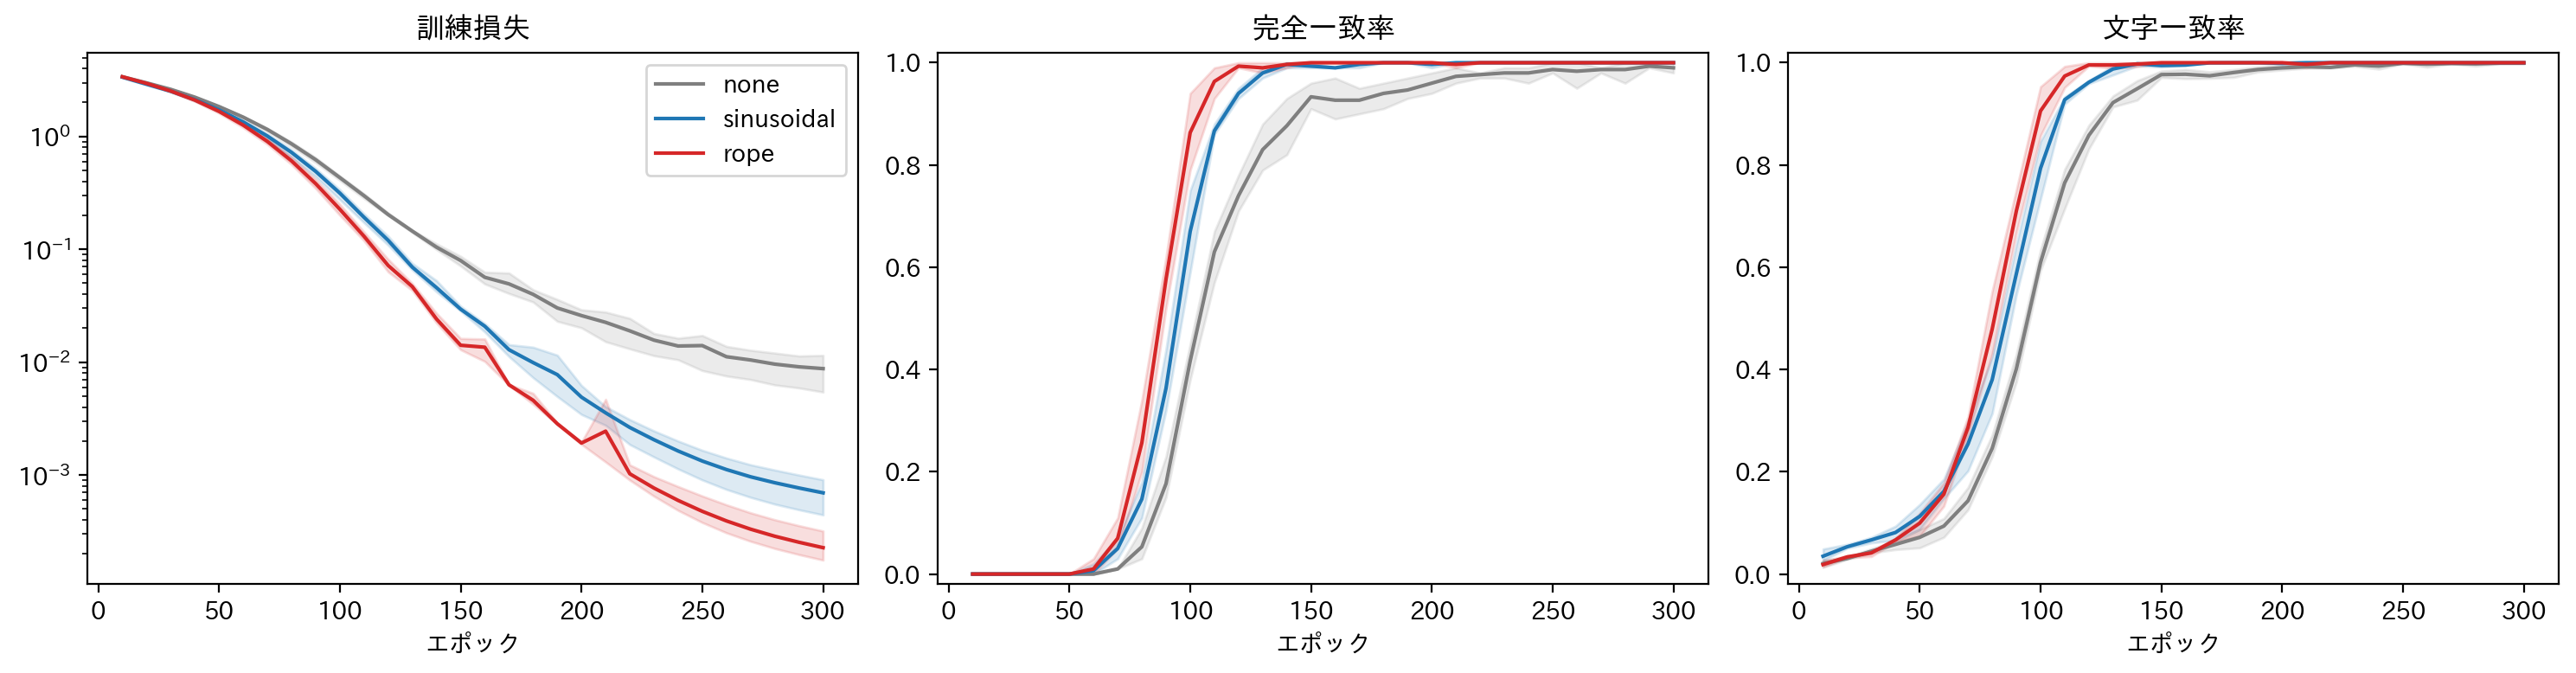

In [5]:
colors = {'none': 'tab:gray', 'sinusoidal': 'tab:blue', 'rope': 'tab:red'}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for pe_type in CONDITIONS:
    H = [results[(pe_type, s)][1] for s in SEEDS]
    ep = H[0]['epoch']
    for ax, key, title in zip(axes, ['loss', 'exact', 'char'], ['訓練損失', '完全一致率', '文字一致率']):
        Y = np.array([h[key] for h in H])
        ax.plot(ep, Y.mean(0), color=colors[pe_type], label=pe_type)
        ax.fill_between(ep, Y.min(0), Y.max(0), color=colors[pe_type], alpha=0.15)
        ax.set_title(title); ax.set_xlabel('エポック')
axes[0].set_yscale('log'); axes[0].legend()
for ax in axes[1:]:
    ax.set_ylim(-0.02, 1.02)
plt.tight_layout(); plt.show()

## 5. 最終結果の表

In [6]:
def first_epoch_reaching(h, thr=0.9):
    """完全一致率が初めて thr 以上になったエポック (到達しなければ None)"""
    for e, a in zip(h['epoch'], h['exact']):
        if a >= thr:
            return e
    return None

print(f'{"条件":>10s} | {"完全一致 (平均)":>14s} | {"各シード":>18s} | {"90% 到達エポック":>16s}')
print('-' * 72)
for pe_type in CONDITIONS:
    H = [results[(pe_type, s)][1] for s in SEEDS]
    ex = [h['exact'][-1] for h in H]
    reach = [first_epoch_reaching(h) for h in H]
    print(f'{pe_type:>10s} | {np.mean(ex):14.3f} | {str([round(x, 2) for x in ex]):>18s} | {str(reach):>16s}')

        条件 |      完全一致 (平均) |               各シード |       90% 到達エポック
------------------------------------------------------------------------
      none |          0.990 |  [0.98, 0.99, 1.0] |  [150, 150, 140]
sinusoidal |          1.000 |    [1.0, 1.0, 1.0] |  [120, 120, 120]
      rope |          1.000 |    [1.0, 1.0, 1.0] |  [110, 100, 110]


## 6. 間違えた歌を見る

シード 0 のモデルについて，各条件で生成を誤った歌を表示する (赤字が誤り)。

In [7]:
from IPython.display import HTML, display

src_all, _, _ = pt.make_tensors(pairs, vocab, DEVICE)
for pe_type in CONDITIONS:
    model = results[(pe_type, 0)][0]
    preds = pt.evaluate(model, src_all, pairs, vocab)['preds']
    rows = []
    for i, ((kami, shimo), p) in enumerate(zip(pairs, preds)):
        if p != shimo:
            colored = ''.join(c if j < len(shimo) and c == shimo[j] else f'<b style="color:red">{c}</b>'
                              for j, c in enumerate(p))
            rows.append(f'<tr><td>{i + 1}</td><td>{kami}</td><td>{shimo}</td><td>{colored}</td></tr>')
    display(HTML(f'<h4>{pe_type}: 誤り {len(rows)} 首</h4>'
                 '<table><tr><th>番号</th><th>上の句</th><th>正解</th><th>生成</th></tr>'
                 + ''.join(rows[:10]) + '</table>'))

番号,上の句,正解,生成
1,あきのたのかりほのいほのとまをあらみ,わかころもてはつゆにぬれつつ,わかころもてはつゆにぬれつつつつ
97,こぬひとをまつほのうらのゆふなきに,やくやもしほのみもこかれつつ,やくやもしほのみもこかれつつつ


番号,上の句,正解,生成


番号,上の句,正解,生成


## 7. デコーダ自己注意の重みを見る

1 首について，下の句を生成するときにデコーダの self-attention が過去のどの位置を見ているかを比べる
(4 ヘッドの平均)。行が現在の位置，列が注意を向けている位置である。因果マスクのため右上は常に 0 になる。

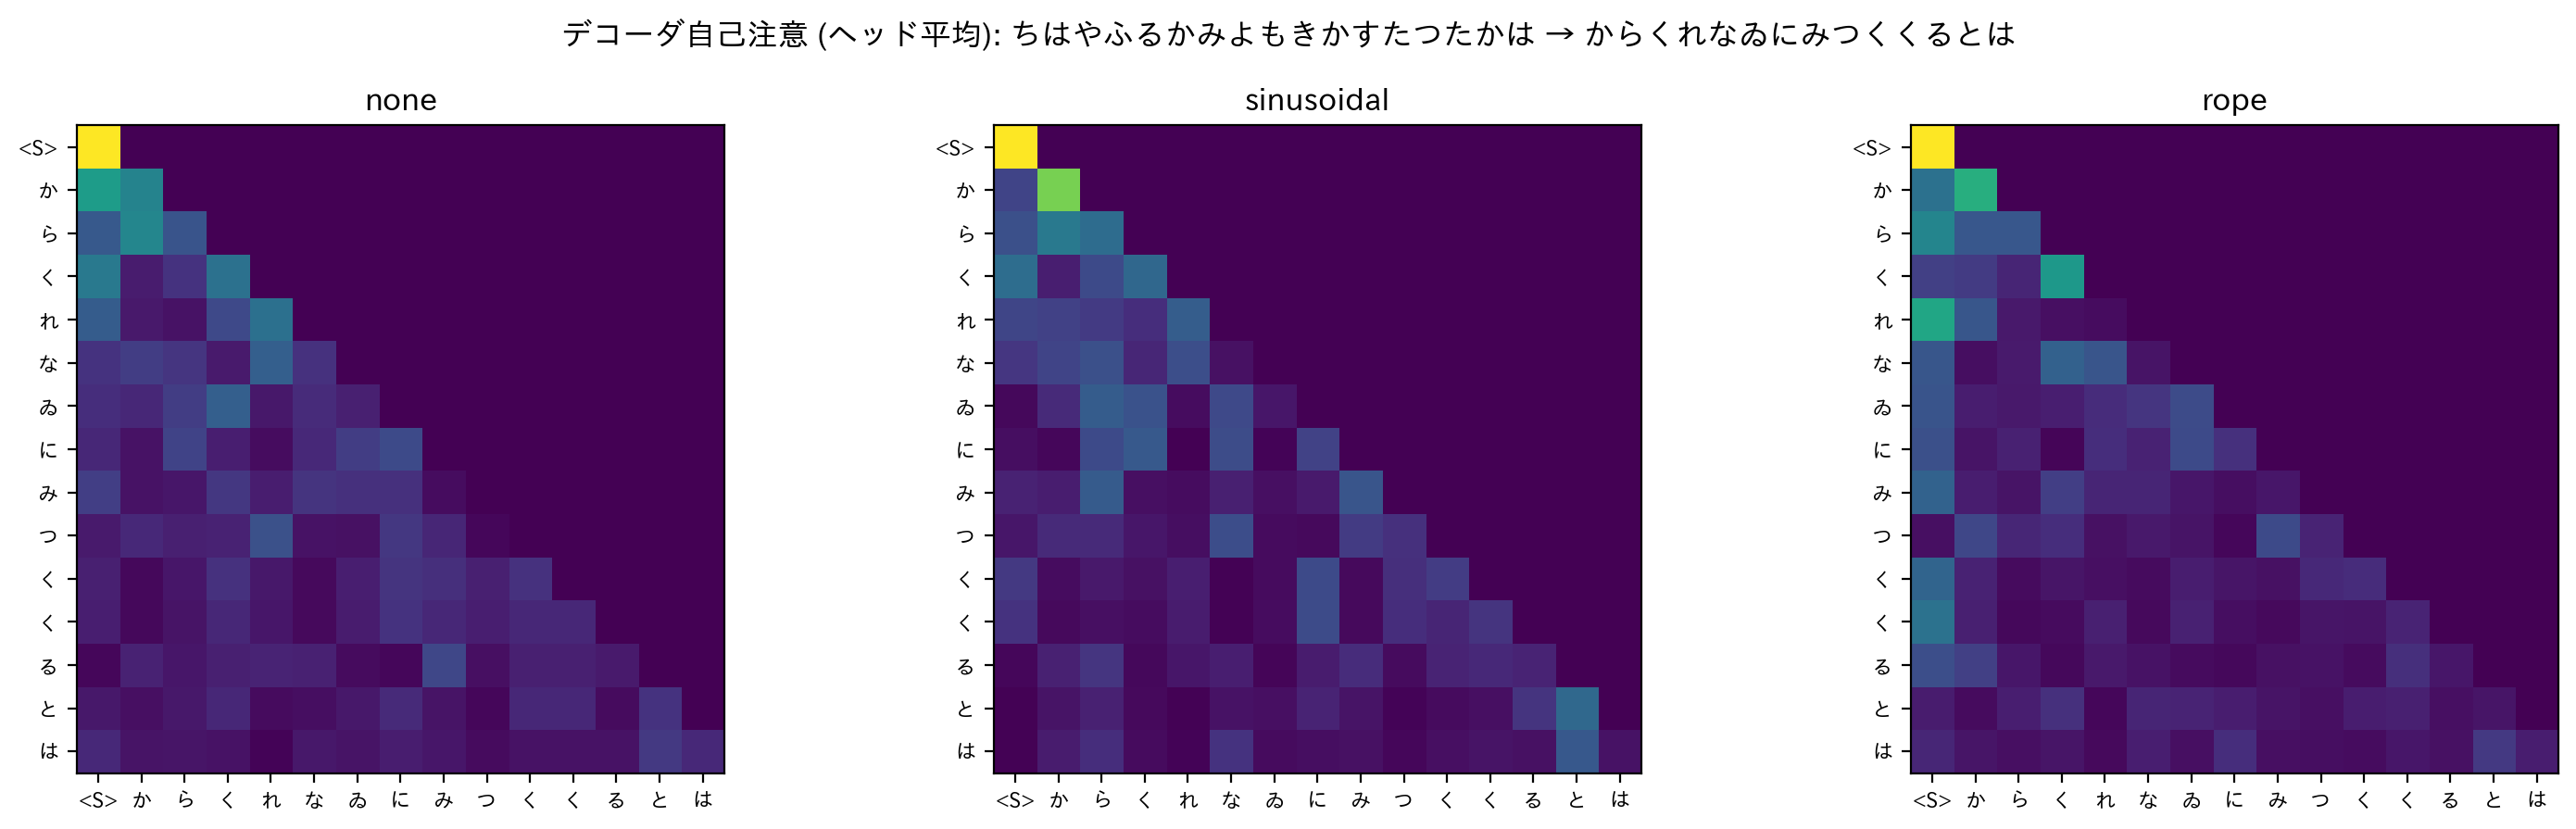

In [8]:
IDX = 16   # 17 番「ちはやふる」(0 始まり)
kami, shimo = pairs[IDX]
src1, tin1, _ = pt.make_tensors([pairs[IDX]], vocab, DEVICE)
labels = ['<S>'] + list(shimo)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, pe_type in zip(axes, CONDITIONS):
    model = results[(pe_type, 0)][0].eval()
    with torch.no_grad():
        model(src1, tin1)
    A = model.decoder_layers[0].self_attn.last_attn[0].mean(0).cpu().numpy()
    ax.imshow(A, cmap='viridis', vmin=0, vmax=1)
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, fontsize=8)
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=8)
    ax.set_title(f'{pe_type}')
fig.suptitle(f'デコーダ自己注意 (ヘッド平均): {kami} → {shimo}')
plt.tight_layout(); plt.show()

## 8. 考えてみよう

1. 3 条件の差は最終的な正解率に出たか，それとも学習の速さに出たか。シード間のばらつきと比べて，その差は大きいか。
2. 6 節で PE なしの誤りを見よ。同じ文字が続く箇所 (「つつ」「くくる」など) や，歌の終わりで誤っていないか。
   「今何文字目か」がわからないと，何ができなくなるか。
3. **PE なしでも高い正解率になるのはなぜか。** ヒント:
   * デコーダには因果マスクがある。位置 $t$ は位置 $0..t$ しか見えないので，「見えている要素の数」から自分の位置をある程度推定できる。
   * エンコーダについては，PE がないと上の句を「文字の集まり (順序なし)」としてしか見られない。それでも 100 首を区別できるか? → `pe_2x2_shuffle.ipynb` で確かめる。
4. 7 節の注意重みは条件によってどう違うか。PE があるときに対角線付近 (直前の文字) に注意が集まるとすれば，それは何を意味するか。
5. この課題は「100 首の丸暗記」であり，汎化を測っていない。PE の違いがもっとはっきり出るのはどのような課題か
   (例: 訓練より長い系列で試す，語順だけが違う入力を区別させる)。